# Análisis exploratorio · Pima Indians Diabetes

José Manuel Barrera Mendoza 

A01797854

--- 

Este notebook contiene únicamente la exploración del conjunto de datos: carga, descripción de las variables, estadísticas descriptivas, visualizaciones y el diagnóstico de calidad de los datos.

El entrenamiento, la evaluación y el registro del experimento viven en `train.py`, en la raíz del repositorio.

Las decisiones de limpieza que se justifican aquí son las que `train.py` implementa dentro del pipeline.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RUTA_DATOS = "../data/pima.csv"

## 1. Carga y descripción del dataset

El conjunto es el **Pima Indians Diabetes Database**, originado en el National Institute of Diabetes and Digestive and Kidney Diseases. Registra mediciones clínicas de mujeres de herencia Pima, mayores de veintiún años, y la variable a predecir indica si la paciente fue diagnosticada con diabetes.

In [2]:
# Lectura de datos con Pandas
datos = pd.read_csv(RUTA_DATOS)

print(f"Registros: {datos.shape[0]}")
print(f"Variables: {datos.shape[1]}")
print()
datos.head()

Registros: 768
Variables: 9



,preg,plas,pres,skin,test,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Significado de cada columna
DICCIONARIO = {
    "preg": ("Pregnancies", "Número de embarazos previos"),
    "plas": ("Glucose", "Glucosa plasmática a las 2 h en prueba de tolerancia oral"),
    "pres": ("BloodPressure", "Presión arterial diastólica (mm Hg)"),
    "skin": ("SkinThickness", "Grosor del pliegue cutáneo del tríceps (mm)"),
    "test": ("Insulin", "Insulina sérica a las 2 h (mu U/ml)"),
    "mass": ("BMI", "Índice de masa corporal (kg/m2)"),
    "pedi": ("DiabetesPedigreeFunction", "Función de pedigrí diabético, antecedentes familiares"),
    "age":  ("Age", "Edad en años"),
    "class":("Outcome", "Diagnóstico de diabetes: 1 positivo, 0 negativo"),
}

resumen = pd.DataFrame(
    [(c, DICCIONARIO[c][0], str(datos[c].dtype), DICCIONARIO[c][1]) for c in datos.columns],
    columns=["columna", "nombre_original", "tipo", "significado"],
)
resumen

,columna,nombre_original,tipo,significado
0,preg,Pregnancies,int64,Número de embarazos previos
1,plas,Glucose,int64,Glucosa plasmática a las 2 h en prueba de tole...
2,pres,BloodPressure,int64,Presión arterial diastólica (mm Hg)
3,skin,SkinThickness,int64,Grosor del pliegue cutáneo del tríceps (mm)
4,test,Insulin,int64,Insulina sérica a las 2 h (mu U/ml)
5,mass,BMI,float64,Índice de masa corporal (kg/m2)
6,pedi,DiabetesPedigreeFunction,float64,"Función de pedigrí diabético, antecedentes fam..."
7,age,Age,int64,Edad en años
8,class,Outcome,int64,"Diagnóstico de diabetes: 1 positivo, 0 negativo"


In [4]:
# Comprobación de nulos declarados y filas duplicadas
print("Valores nulos declarados por pandas:")
print(datos.isna().sum().to_string())
print(f"\nFilas duplicadas exactas: {datos.duplicated().sum()}")

Valores nulos declarados por pandas:
preg     0
plas     0
pres     0
skin     0
test     0
mass     0
pedi     0
age      0
class    0

Filas duplicadas exactas: 0


In [5]:
# Descripción estadística de las variables
datos.describe().T

,count,mean,std,min,25%,50%,75%,max
preg,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
plas,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
pres,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
skin,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
test,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
mass,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
pedi,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
class,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


### Hallazgos de la primera lectura

1. Pandas no reporta ningún valor nulo y no hay filas duplicadas. El archivo parece limpio.
2. La estadística descriptiva desmiente lo anterior: las columnas `plas`, `pres`, `skin`, `test` y `mass` tienen cero como valor mínimo, y cero es clínicamente imposible en todas ellas. Nadie tiene presión arterial diastólica de cero ni índice de masa corporal de cero. Esos ceros son valores faltantes codificados como cero.

## 2. Análisis exploratorio

El objetivo aquí es triple: medir el desbalance de la variable objetivo, cuantificar la magnitud real de los faltantes y entender qué variables separan a las dos clases.

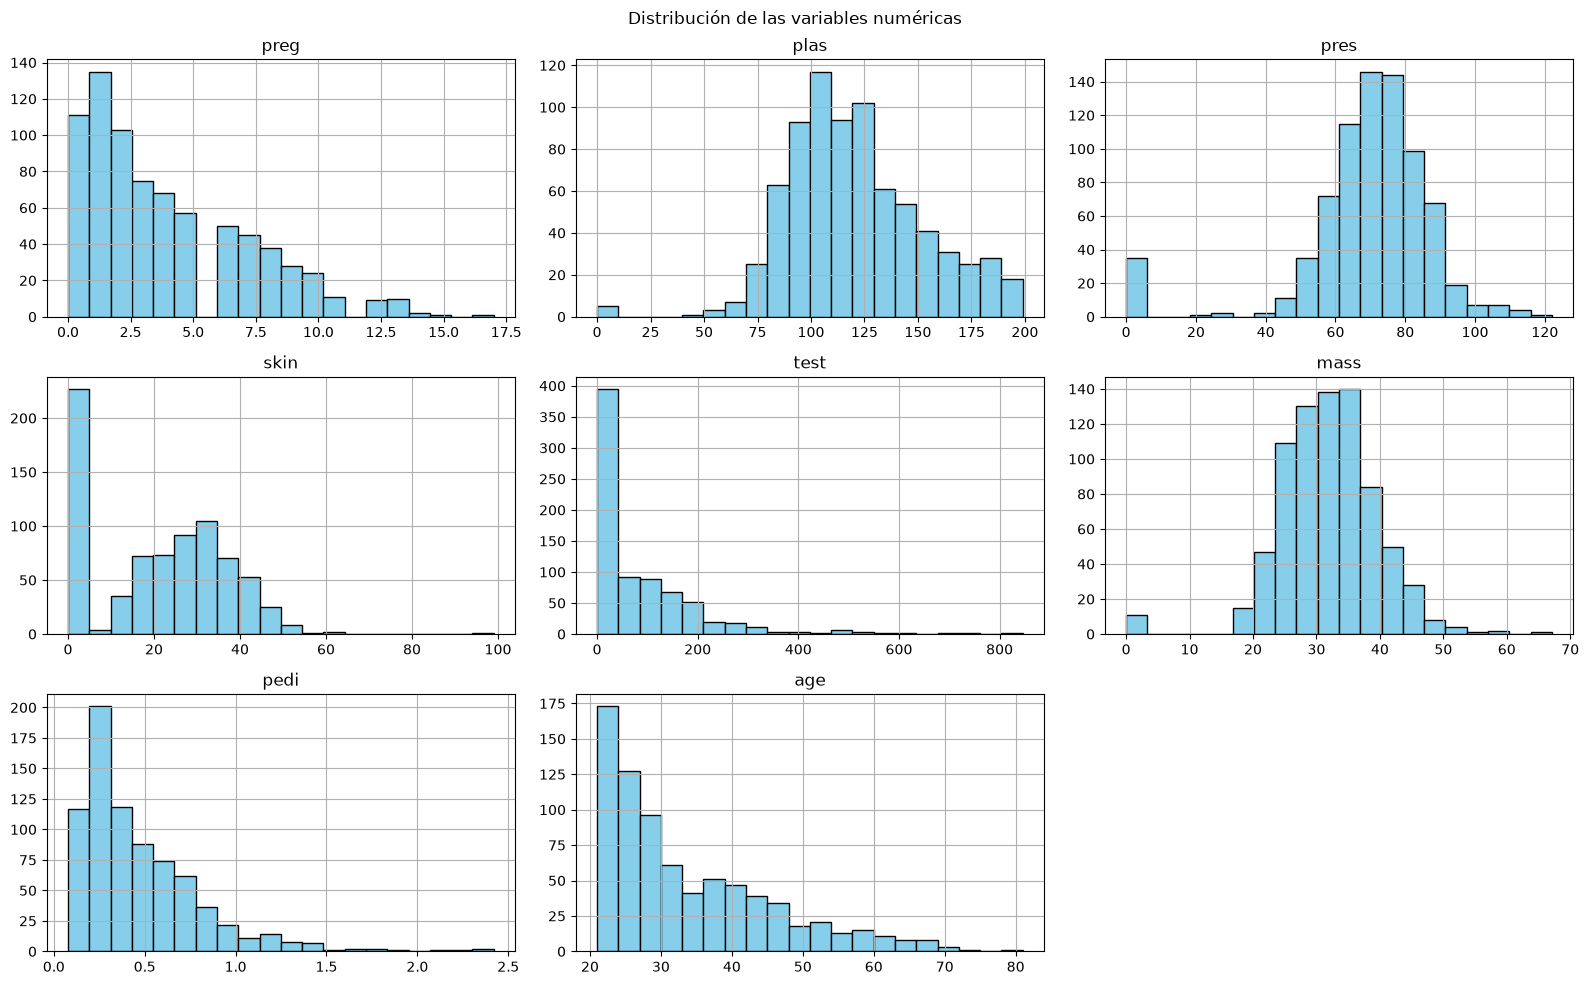

In [6]:
# Histogramas de las variables numéricas
datos.drop(columns=["class"]).hist(
    bins=20, figsize=(16, 10),
    color="skyblue", edgecolor="black"
)
plt.suptitle("Distribución de las variables numéricas")
plt.tight_layout()
plt.show()

Distribución de la clase:
  0 negativo (sin diabetes)   :  500 casos  (65.1 %)
  1 positivo (con diabetes)   :  268 casos  (34.9 %)

Un clasificador que siempre prediga la clase mayoritaria acierta 65.1 % de las veces.
Esa es la vara: cualquier modelo que no la supere no aporta nada.


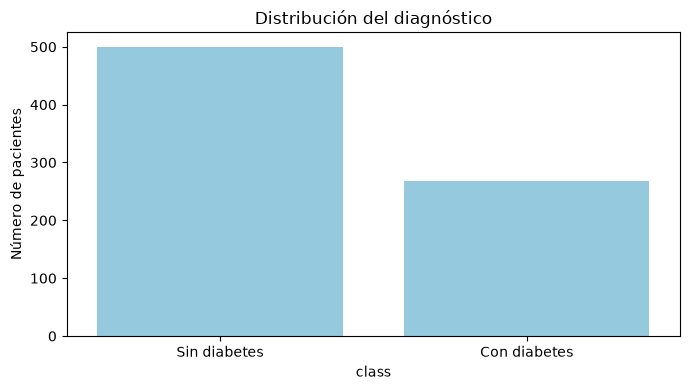

In [7]:
# Distribución de la variable objetivo
conteo = datos["class"].value_counts().sort_index()
proporcion = datos["class"].value_counts(normalize=True).sort_index()
vara_mayoritaria = proporcion.max()

print("Distribución de la clase:")
for valor in conteo.index:
    etiqueta = "negativo (sin diabetes)" if valor == 0 else "positivo (con diabetes)"
    print(f"  {valor} {etiqueta:26s}: {conteo[valor]:4d} casos  ({proporcion[valor]*100:.1f} %)")
print(f"\nUn clasificador que siempre prediga la clase mayoritaria acierta {vara_mayoritaria*100:.1f} % de las veces.")
print("Esa es la vara: cualquier modelo que no la supere no aporta nada.")

plt.figure(figsize=(7, 4))
sns.countplot(data=datos, x="class", order=[0, 1], color="skyblue")
plt.xticks([0, 1], ["Sin diabetes", "Con diabetes"])
plt.title("Distribución del diagnóstico")
plt.ylabel("Número de pacientes")
plt.tight_layout()
plt.show()

      ceros  porcentaje       interpretacion
preg    111        14.5       Valor legítimo
plas      5         0.7  Faltante disfrazado
pres     35         4.6  Faltante disfrazado
skin    227        29.6  Faltante disfrazado
test    374        48.7  Faltante disfrazado
mass     11         1.4  Faltante disfrazado
pedi      0         0.0            Sin ceros
age       0         0.0            Sin ceros


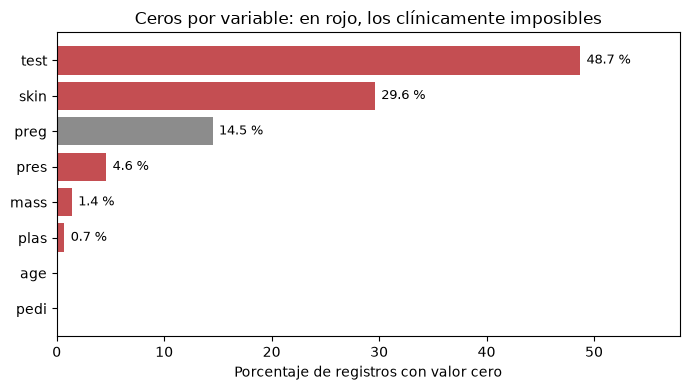

In [8]:
# Cuantificación de los ceros, separando los imposibles de los legítimos
COLUMNAS_CERO_IMPOSIBLE = ["plas", "pres", "skin", "test", "mass"]

ceros = pd.DataFrame({
    "ceros": (datos == 0).sum(),
    "porcentaje": ((datos == 0).mean() * 100).round(1),
})
ceros["interpretacion"] = [
    "Faltante disfrazado" if c in COLUMNAS_CERO_IMPOSIBLE
    else ("Valor legítimo" if c in ("preg", "class") else "Sin ceros")
    for c in ceros.index
]
ceros_vista = ceros.drop(index="class")
print(ceros_vista.to_string())

fig, eje = plt.subplots(figsize=(7, 4))
orden = ceros_vista.sort_values("porcentaje", ascending=True)
colores = ["#c44e52" if i in COLUMNAS_CERO_IMPOSIBLE else "#8c8c8c" for i in orden.index]
eje.barh(orden.index, orden["porcentaje"], color=colores)
for i, (idx, fila) in enumerate(orden.iterrows()):
    if fila["porcentaje"] > 0:
        eje.text(fila["porcentaje"] + 0.6, i, f"{fila['porcentaje']:.1f} %", va="center", fontsize=9)
eje.set_xlabel("Porcentaje de registros con valor cero")
eje.set_title("Ceros por variable: en rojo, los clínicamente imposibles")
eje.set_xlim(0, 58)
fig.tight_layout()
plt.show()

La gráfica separa dos situaciones que se ven iguales en los datos y no lo son.

En gris, `preg` tiene ceros en el 14.5 % de los registros y son **legítimos**: corresponden a mujeres sin embarazos previos. Imputarlos sería inventar embarazos que no ocurrieron y destruir información real.

En rojo, las cinco variables clínicas donde el cero es imposible. La magnitud varía muchísimo, desde el 0.7 % de la glucosa hasta el 48.7 % de la insulina, y esa variación es justo lo que obliga a mirar cada una por separado en lugar de aplicar una regla única.

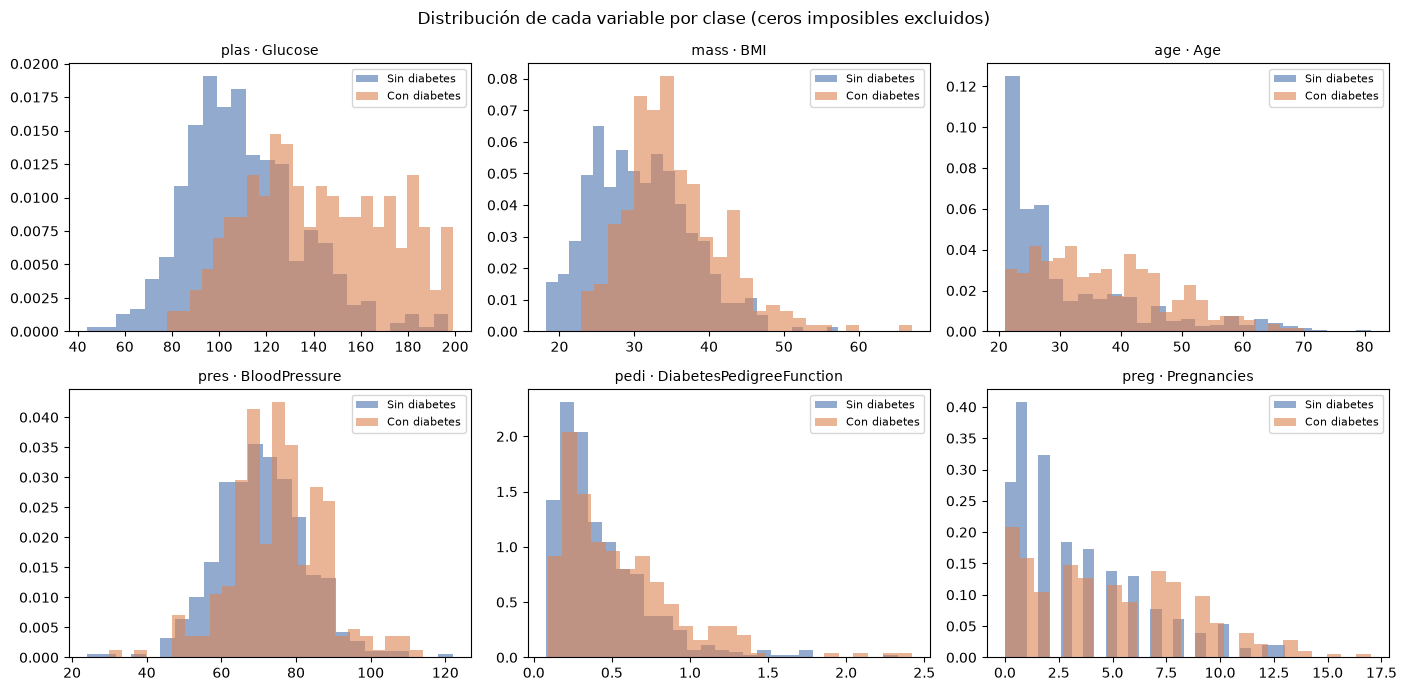

In [9]:
# Distribución de las variables continuas por clase, ignorando los ceros imposibles
datos_vista = datos.copy()
datos_vista[COLUMNAS_CERO_IMPOSIBLE] = datos_vista[COLUMNAS_CERO_IMPOSIBLE].replace(0, np.nan)

variables = ["plas", "mass", "age", "pres", "pedi", "preg"]
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for eje, var in zip(ejes.ravel(), variables):
    for clase, color, etiqueta in [(0, "#4c72b0", "Sin diabetes"), (1, "#dd8452", "Con diabetes")]:
        serie = datos_vista.loc[datos_vista["class"] == clase, var].dropna()
        eje.hist(serie, bins=25, alpha=0.6, color=color, label=etiqueta, density=True)
    eje.set_title(f"{var} · {DICCIONARIO[var][0]}", fontsize=10)
    eje.legend(fontsize=8)
fig.suptitle("Distribución de cada variable por clase (ceros imposibles excluidos)", fontsize=12)
fig.tight_layout()
plt.show()

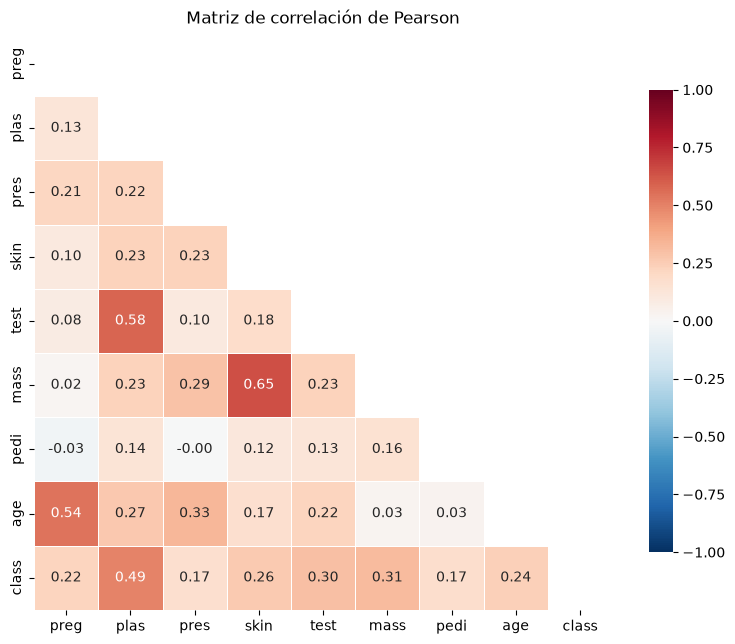

Correlación de cada variable con el diagnóstico, de mayor a menor:
plas    0.495
mass    0.314
test    0.303
skin    0.259
age     0.238
preg    0.222
pedi    0.174
pres    0.171


In [10]:
# Correlaciones entre variables, calculadas sin los ceros imposibles
correlacion = datos_vista.corr(numeric_only=True)

fig, eje = plt.subplots(figsize=(8, 6.5))
mascara = np.triu(np.ones_like(correlacion, dtype=bool))
sns.heatmap(correlacion, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=.5, cbar_kws={"shrink": .8}, ax=eje)
eje.set_title("Matriz de correlación de Pearson")
fig.tight_layout()
plt.show()

print("Correlación de cada variable con el diagnóstico, de mayor a menor:")
print(correlacion["class"].drop("class").sort_values(ascending=False).round(3).to_string())

Tres lecturas del exploratorio.

La glucosa es, con diferencia, la variable más asociada al diagnóstico, lo cual es coherente con la literatura clínica.

Los histogramas muestran que ninguna variable separa las clases por sí sola. Hay traslape en todas, aunque en glucosa el desplazamiento entre ambas distribuciones es visible a simple vista.

Las correlaciones entre predictores son moderadas. La más alta es entre grosor del pliegue cutáneo e índice de masa corporal, lo cual tiene sentido porque ambas miden adiposidad. No hay multicolinealidad severa que obligue a eliminar variables en un baseline.

## 3. Diagnóstico de calidad de los datos

Cuatro revisiones: faltantes, duplicados, valores atípicos y tipos de dato.

In [11]:
# Faltantes reales, una vez interpretados los ceros imposibles
print("Valores faltantes por variable:")
print(datos_vista.isna().sum().to_string())
print(f"\nTotal de faltantes: {int(datos_vista[COLUMNAS_CERO_IMPOSIBLE].isna().sum().sum())}")

# Duplicados
print(f"\nFilas duplicadas: {datos_vista.duplicated().sum()}")

# Valores atípicos por el criterio del rango intercuartílico
numericas = [c for c in datos_vista.columns if c != "class"]
q1 = datos_vista[numericas].quantile(0.25)
q3 = datos_vista[numericas].quantile(0.75)
iqr = q3 - q1
fuera = ((datos_vista[numericas] < (q1 - 1.5 * iqr)) | (datos_vista[numericas] > (q3 + 1.5 * iqr))).sum()
print("\nValores fuera del rango intercuartílico ampliado:")
print(fuera.to_string())

# Tipos de dato
print("\nTipos de dato:")
print(datos_vista.dtypes.to_string())

Valores faltantes por variable:
preg       0
plas       5
pres      35
skin     227
test     374
mass      11
pedi       0
age        0
class      0

Total de faltantes: 652

Filas duplicadas: 0

Valores fuera del rango intercuartílico ampliado:
preg     4
plas     0
pres    14
skin     3
test    24
mass     8
pedi    29
age      9

Tipos de dato:
preg       int64
plas     float64
pres     float64
skin     float64
test     float64
mass     float64
pedi     float64
age        int64
class      int64


## 4. train.py

| Problema | Decisión | Por qué |
| --- | --- | --- |
| Ceros imposibles en `plas`, `pres`, `skin`, `test` y `mass` | Tratarlos como faltantes e imputarlos | Son faltantes codificados como cero, no mediciones |
| Ceros en `preg` | Conservarlos | Son legítimos: indican que no hubo embarazos previos |
| Duplicados | Nada que hacer | No hay ninguno |
| Valores atípicos | Conservarlos | En datos clínicos un valor extremo suele ser un paciente real en situación extrema, no un error de captura. Eliminarlos sesgaría el modelo contra los casos más graves, que son justo los que más importa detectar |
| Tipos de dato | Nada que hacer | Todas las columnas son numéricas, sin conversiones pendientes |
| Desbalance de clases, 65 contra 35 | Ponderar las clases en el modelo | No detectar a una paciente diabética cuesta más que una falsa alarma |

Para reproducir el entrenamiento:

```bash
python train.py
```